# Experiment 3: Breadth-first and depth-first search
Aniruddh Vijayvargia (500125613), Batch D. Lab Manual, Chapter 4.

A 23 x 35 maze is carved with randomized depth-first search (seed 613),
then searched by one function whose only switch is the end of the frontier.

In [1]:
import json, os, platform
from collections import deque
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

os.makedirs("figs", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "font.size": 10})
R = {"versions": {"python": platform.python_version(), "numpy": np.__version__,
                  "matplotlib": matplotlib.__version__}}

In [2]:
def carve_maze(h, w, seed, extra_openings=0.06):
    """Randomized DFS carver on odd cells; a few walls are then knocked out
    so the maze has loops and BFS and DFS can find different paths."""
    rng = np.random.default_rng(seed)
    m = np.ones((h, w), dtype=int)
    stack = [(1, 1)]; m[1, 1] = 0
    while stack:
        r, c = stack[-1]
        nbrs = [(r + dr, c + dc, dr, dc) for dr, dc in ((-2, 0), (2, 0), (0, -2), (0, 2))
                if 0 < r + dr < h - 1 and 0 < c + dc < w - 1 and m[r + dr, c + dc] == 1]
        if not nbrs:
            stack.pop(); continue
        nr, nc, dr, dc = nbrs[rng.integers(len(nbrs))]
        m[r + dr // 2, c + dc // 2] = 0; m[nr, nc] = 0
        stack.append((nr, nc))
    inner = [(r, c) for r in range(1, h - 1) for c in range(1, w - 1)
             if m[r, c] == 1 and ((m[r - 1, c] == 0 and m[r + 1, c] == 0) or (m[r, c - 1] == 0 and m[r, c + 1] == 0))]
    for k in rng.choice(len(inner), int(extra_openings * len(inner)), replace=False):
        m[inner[k]] = 0
    return m

maze = carve_maze(23, 35, seed=613)
H, W = maze.shape
START, GOAL = (1, 1), (H - 2, W - 2)
R["maze"] = {"rows": H, "cols": W, "open_cells": int((maze == 0).sum())}
print(R["maze"])

{'rows': 23, 'cols': 35, 'open_cells': 387}


In [3]:
def neighbours(cell):
    r, c = cell
    for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):      # up, down, left, right
        nr, nc = r + dr, c + dc
        if 0 <= nr < H and 0 <= nc < W:                   # bounds first ...
            if maze[nr, nc] == 0:                         # ... then contents
                yield (nr, nc)

def search(start, goal, mode="bfs"):
    frontier = deque([start])
    parent = {start: None}            # marks a cell as discovered when it is enqueued
    order = {}                        # cell -> step at which it was expanded
    frontier_size = []                # frontier length before each expansion
    while frontier:
        frontier_size.append(len(frontier))
        node = frontier.popleft() if mode == "bfs" else frontier.pop()   # the only difference
        if node in order:
            continue
        order[node] = len(order)
        if node == goal:
            break
        for nxt in neighbours(node):
            if nxt not in parent:
                parent[nxt] = node
                frontier.append(nxt)
    path, cur = [], goal
    if goal in parent:
        while cur is not None:
            path.append(cur); cur = parent[cur]
    return order, path[::-1], frontier_size

def validate(path):
    """Every step adjacent (Manhattan distance 1), no step on a wall, ends correct."""
    ok_ends = bool(path) and path[0] == START and path[-1] == GOAL
    ok_adj = all(abs(a[0] - b[0]) + abs(a[1] - b[1]) == 1 for a, b in zip(path, path[1:]))
    ok_open = all(maze[r, c] == 0 for r, c in path)
    return ok_ends and ok_adj and ok_open

res = {}
for mode in ("bfs", "dfs"):
    order, path, fsize = search(START, GOAL, mode)
    res[mode] = (order, path, fsize)
    R[mode] = {"expanded": len(order), "path_cells": len(path), "path_steps": len(path) - 1,
               "valid": validate(path), "max_frontier": max(fsize), "mean_frontier": float(np.mean(fsize))}
    print(mode.upper(), R[mode])

BFS {'expanded': 282, 'path_cells': 53, 'path_steps': 52, 'valid': True, 'max_frontier': 11, 'mean_frontier': 7.379432624113475}
DFS {'expanded': 99, 'path_cells': 91, 'path_steps': 90, 'valid': True, 'max_frontier': 12, 'mean_frontier': 6.474747474747475}


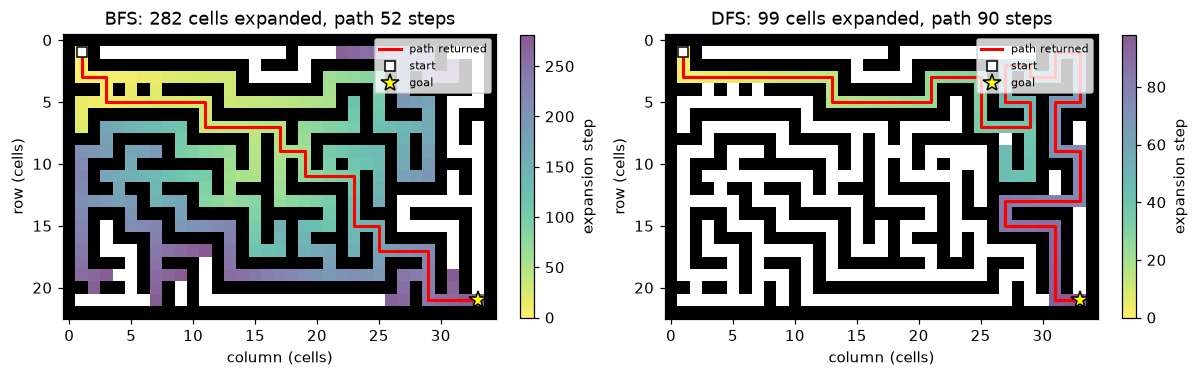

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, mode in zip(axes, ("bfs", "dfs")):
    order, path, _ = res[mode]
    grid = np.full(maze.shape, np.nan)
    for (r, c), k in order.items():
        grid[r, c] = k
    ax.imshow(maze, cmap="binary", interpolation="nearest")
    im = ax.imshow(grid, cmap="viridis_r", alpha=0.65, interpolation="nearest")
    ax.plot([c for _, c in path], [r for r, _ in path], lw=2, color="red", label="path returned")
    ax.plot(START[1], START[0], "s", color="w", mec="k", ms=7, label="start")
    ax.plot(GOAL[1], GOAL[0], "*", color="yellow", mec="k", ms=12, label="goal")
    ax.set_title(f"{mode.upper()}: {len(order)} cells expanded, path {len(path) - 1} steps")
    ax.set_xlabel("column (cells)"); ax.set_ylabel("row (cells)")
    ax.legend(fontsize=7, loc="upper right")
    fig.colorbar(im, ax=ax, fraction=0.03, label="expansion step")
fig.tight_layout(); fig.savefig("figs/fig3_1_maze_paths.png")

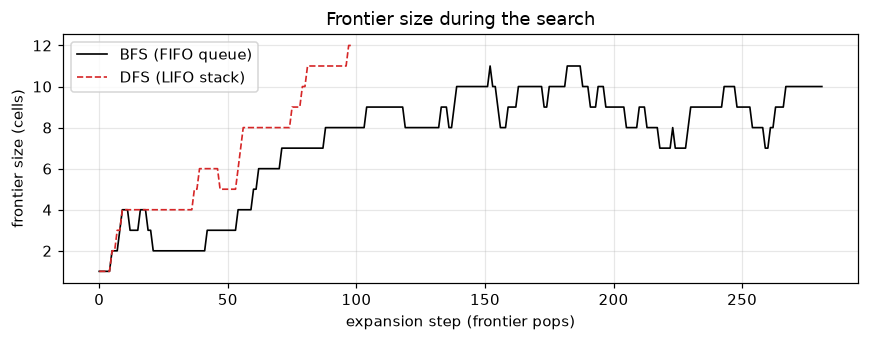

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(res["bfs"][2], lw=1.1, color="k", label="BFS (FIFO queue)")
ax.plot(res["dfs"][2], lw=1.1, ls="--", color="tab:red", label="DFS (LIFO stack)")
ax.set_xlabel("expansion step (frontier pops)"); ax.set_ylabel("frontier size (cells)")
ax.set_title("Frontier size during the search"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figs/fig3_2_frontier.png")

In [6]:
with open("results.json", "w") as fh:
    json.dump(R, fh, indent=2)
print("saved results.json")

saved results.json
